### Problem 8 : Approximate Unlearning - fine-tuning, gradient ascent, and the traps

⏱️ ~35 min · 🧭 Stage 4 (Approximate unlearning), rung 6 · 📄 `resources/papers/05-llm-unlearning/2022-jang-knowledge-unlearning-lms.pdf`, `03-approximate-unlearning/2023-kurmanji-scrub…` (NegGrad+)

> 🔗 **Building on Problems 2, 6 and 7 :** exact unlearning for networks means retraining (expensive, Problem 6) or SISA
> (cheap, but only if planned before training, Problem 7). Most production models were trained monolithically long
> ago. A deletion request arrives *today*. We need to edit the model we already have.

Go back to the Newton step of Problem 2. It said : *move the weights in the direction the deleted points were pulling
them, scaled by the curvature of what remains* :

**w_new = w + H_r⁻¹ · Σ_{deleted} ∇ℓᵢ(w)**

A network has no usable Hessian `H_r` (Problem 4: 29 GB for this toy). So drop it - replace `H_r⁻¹` by a small step size
`η`. What is left is :

**w_new = w + η · Σ_{deleted} ∇ℓᵢ(w)**

That is **gradient ascent** on the forget set - "train the model to get *worse* on Carol". It is the most popular
unlearning baseline there is, and this problem shows why it is both natural and dangerous. We will try, in order :

| Method | One-line idea | Lineage |
|---|---|---|
| **Fine-tune** on D_r | keep training without Carol; hope she fades | the warm-start trap of Problem 6 |
| **Gradient ascent** on D_f | climb Carol's loss | Newton step **without curvature** |
| **NegGrad+** | climb Carol's loss *and* descend on D_r in every step | gradient ascent with an **anchor** |

**TASK :** Make the network forget Carol with these three methods, track them step by step against the gold band, and
find out which ones pass the audit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, train, methods, classical, audit, nn, viz
viz.style()

L = lab.make_lab("carol")
splits = L.splits()
original = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)

# The gold band (Problem 6) and the reference models for the per-example audit (Problem 5)
OUT = [train.fit(lab.model_fn, L.Xr, L.yr, seed=s, **lab.FIT) for s in range(100, 112)]
IN = [train.fit(lab.model_fn, L.X_train, L.y_train, seed=s, **lab.FIT) for s in range(1, 9)]
band_mean, band_std = audit.gold_band(OUT, splits, in_models=IN, mia=False)
lo, hi = band_mean["forget_acc"] - 2 * band_std["forget_acc"], band_mean["forget_acc"] + 2 * band_std["forget_acc"]
print(f"gold band for accuracy on Carol: {lo:.1%} - {hi:.1%}   (original model: {train.accuracy(original, L.Xf, L.yf):.1%})")

gold band for accuracy on Carol: 53.3% - 72.2%   (original model: 100.0%)


#### First, the bridge : gradient ascent on the *convex* model from Problem 2

Before touching the network, let's check that "Newton minus curvature" really is gradient ascent, on the logistic
regression we can still solve exactly.

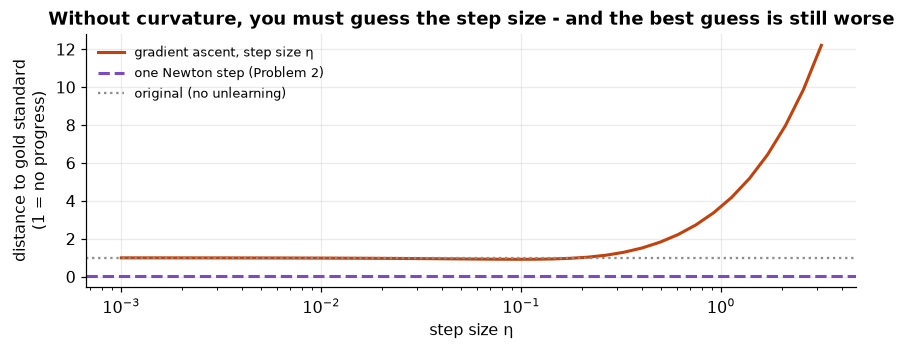

best gradient-ascent step closes 8% of the gap; the Newton step closes 95%. Too small a step: no progress. Too large: overshoot.


In [2]:
# Gradient ascent on logistic regression: w + eta * (sum of Carol's loss gradients)
lam = 1.0
lr_full = classical.SoftmaxNewton(lam).fit(L.X_train, L.y_train)
lr_gold = classical.SoftmaxNewton(lam).fit(L.Xr, L.yr)
lr_newton = lr_full.unlearn_newton(L.Xr, L.yr, steps=1)
g_forget = lr_full.grad(lr_full.w, L.Xf, L.yf) - lam * lr_full.w          # Σ ∇ℓᵢ over Carol's digits (no regulariser)

gap0 = np.linalg.norm(lr_full.w - lr_gold.w)
etas = np.logspace(-3, 0.5, 40)
gaps = [np.linalg.norm(lr_full.w + eta * g_forget - lr_gold.w) for eta in etas]
best = int(np.argmin(gaps))

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.semilogx(etas, np.array(gaps) / gap0, color=viz.color_for("gradient_ascent"), lw=2, label="gradient ascent, step size η")
ax.axhline(np.linalg.norm(lr_newton.w - lr_gold.w) / gap0, color=viz.METHOD, ls="--", lw=2, label="one Newton step (Problem 2)")
ax.axhline(1, color=viz.ORIGINAL, ls=":", label="original (no unlearning)")
ax.set_xlabel("step size η"); ax.set_ylabel("distance to gold standard\n(1 = no progress)"); ax.legend(fontsize=8.5)
ax.set_title("Without curvature, you must guess the step size - and the best guess is still worse"); plt.tight_layout(); plt.show()
print(f"best gradient-ascent step closes {1 - gaps[best] / gap0:.0%} of the gap; the Newton step closes "
      f"{1 - np.linalg.norm(lr_newton.w - lr_gold.w) / gap0:.0%}. Too small a step: no progress. Too large: overshoot.")

**Read that again.** On the *easiest possible* model, the best gradient-ascent step closes only a small fraction of the
gap that one Newton step closes almost entirely. Two lessons :

1. Without curvature there is a **step size to choose**, and nothing in the method tells you the right one.
2. The curvature is not a refinement - it is most of the answer. The deleted points' raw gradient points in the
   *wrong direction*; `H_r⁻¹` is what turns it towards the retrained model.

Now the network, where there is no gold standard to tune against in real life.

#### Step 1 : Train - done above (`original`). Step 2 : the issue - Carol at 100%, the band far lower.

#### Step 3 : Untrain - three methods, tracked epoch by epoch

In [3]:
# Step 3: run each method for several epochs and record where it is after every one
def track(step_fn, model, n_epochs):
    hist, m = [], model
    for _ in range(n_epochs):
        m = step_fn(m)
        hist.append((train.accuracy(m, L.Xf, L.yf), train.accuracy(m, L.X_test, L.y_test)))
    return m, np.array(hist)

runs = {}
runs["finetune"] = track(lambda m: methods.finetune(m, L.Xr, L.yr, epochs=1, lr=1e-3)[0], original, 12)
runs["gradient_ascent"] = track(lambda m: methods.gradient_ascent(m, L.Xf, L.yf, epochs=1, lr=3e-4)[0], original, 12)
runs["neggrad+"] = track(lambda m: methods.neggrad_plus(m, L.Xr, L.yr, L.Xf, L.yf, epochs=1, alpha=0.99, lr=1e-3)[0], original, 12)

#### Step 4 : Show the result - the trajectories

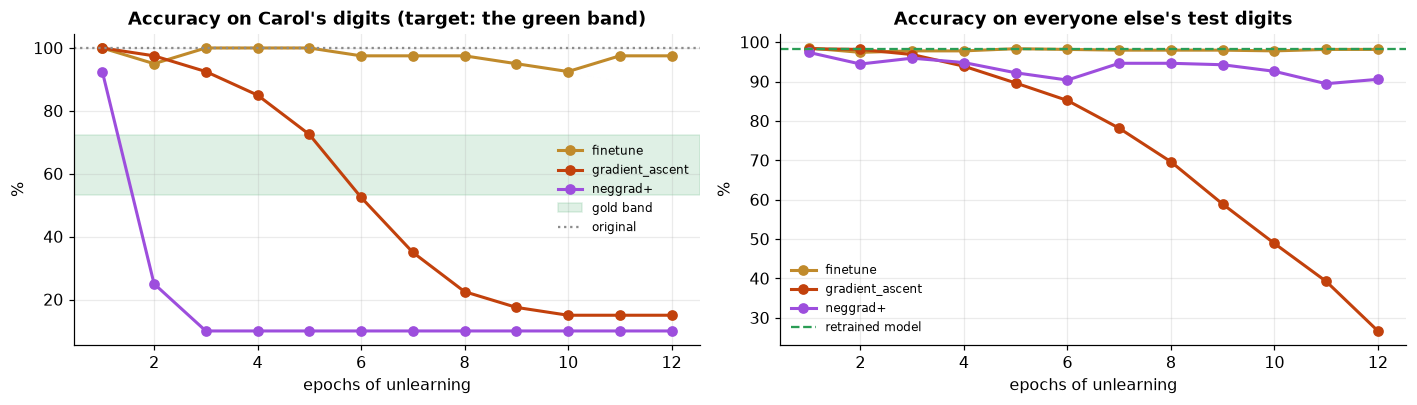

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, (_, h) in runs.items():
    ep = np.arange(1, len(h) + 1)
    axes[0].plot(ep, 100 * h[:, 0], "o-", color=viz.color_for(name), lw=2, label=name)
    axes[1].plot(ep, 100 * h[:, 1], "o-", color=viz.color_for(name), lw=2, label=name)
axes[0].axhspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="gold band")
axes[0].axhline(100 * train.accuracy(original, L.Xf, L.yf), color=viz.ORIGINAL, ls=":", label="original")
axes[0].set_title("Accuracy on Carol's digits (target: the green band)"); axes[0].set_xlabel("epochs of unlearning"); axes[0].set_ylabel("%")
axes[1].axhline(100 * band_mean["test_acc"], color=viz.RETRAIN, ls="--", label="retrained model")
axes[1].set_title("Accuracy on everyone else's test digits"); axes[1].set_xlabel("epochs of unlearning"); axes[1].set_ylabel("%")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

Three very different behaviours :

- **Fine-tuning** barely moves Carol - forgetting by neglect is far too slow for memorised data (the Problem 6 trap).
- **Gradient ascent** does push Carol's accuracy down... and drags everyone else's down with it. There is no brake :
  nothing in "make Carol's loss bigger" says *stop when you reach the band*. Keep going and the whole model collapses -
  the fastest way to make a model forget Carol is to make it forget **everything**.
- **NegGrad+** adds an anchor : every ascent step on Carol is paired with a descent step on everyone else, which keeps
  the rest of the model in place while Carol is pushed out.

In [5]:
# How far does gradient ascent fall if nobody stops it ?
_, h_long = track(lambda m: methods.gradient_ascent(m, L.Xf, L.yf, epochs=1, lr=1e-3)[0], original, 15)
print("gradient ascent with a larger step (lr=1e-3), test accuracy after each epoch:")
print("  " + "  ".join(f"{a:.0%}" for a in h_long[:, 1]))

gradient ascent with a larger step (lr=1e-3), test accuracy after each epoch:
  98%  89%  66%  44%  31%  30%  29%  26%  15%  10%  10%  10%  10%  10%  10%


#### Step 5 : Prove it - the audit (gold band + per-example U-LiRA + utility)

Now we score each method at a reasonable stopping point with the full audit from Problems 5-6.

In [6]:
# Step 5: candidate stopping points, scored by the same gate used throughout
candidates = {
    "original": original,
    "retrain": train.fit(lab.model_fn, L.Xr, L.yr, seed=999, **lab.FIT),
    "finetune (5 ep)": methods.finetune(original, L.Xr, L.yr, epochs=5)[0],
    "gradient_ascent (3 ep)": methods.gradient_ascent(original, L.Xf, L.yf, epochs=3, lr=3e-4)[0],
    "gradient_ascent (10 ep)": methods.gradient_ascent(original, L.Xf, L.yf, epochs=10, lr=3e-4)[0],
    "neggrad+ (2 ep)": methods.neggrad_plus(original, L.Xr, L.yr, L.Xf, L.yf, epochs=2, alpha=0.99, lr=1e-3)[0],
    "neggrad+ (3 ep)": methods.neggrad_plus(original, L.Xr, L.yr, L.Xf, L.yf, epochs=3, alpha=0.99, lr=1e-3)[0],
}
table = audit.audit(candidates, splits, OUT, in_models=IN, mia=False)
verdict = audit.gate(table, band_mean, band_std)
print(f"gold band: Carol {band_mean['forget_acc']:.1%} ± {2 * band_std['forget_acc']:.1%}, "
      f"U-LiRA ≤ {band_mean['ulira'] + max(2 * band_std['ulira'], 0.10):.2f}, test ≥ {band_mean['test_acc'] - 0.02:.1%}\n")
print(table[["forget_acc", "test_acc", "ulira"]].join(verdict).round(3).to_string())

gold band: Carol 62.7% ± 9.5%, U-LiRA ≤ 0.20, test ≥ 96.4%

                         forget_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict
method                                                                             
original                      1.000     0.980  0.950      x       x      ok    FAIL
retrain                       0.625     0.980  0.075     ok      ok      ok    PASS
finetune (5 ep)               1.000     0.981  0.875      x       x      ok    FAIL
gradient_ascent (3 ep)        0.950     0.980  0.575      x       x      ok    FAIL
gradient_ascent (10 ep)       0.275     0.687  0.025      x      ok       x    FAIL
neggrad+ (2 ep)               0.650     0.969  0.200     ok      ok      ok    PASS
neggrad+ (3 ep)               0.125     0.952  0.000      x      ok       x    FAIL


Read the verdict column with the trajectories in mind :

- *Under-forgetting* (fine-tune, short gradient ascent) fails **FORGET** and **PRIVACY** - Carol is still in there.
- *Collateral damage* (long gradient ascent) fails **UTILITY** - the model got worse for everyone.
- *Over-forgetting* (NegGrad+ one epoch too long) fails **FORGET** - pushing Carol *below* the band is as suspicious as
  leaving her above it - and starts to cost utility too.
- NegGrad+ stopped after exactly 2 epochs passes. One epoch more and it fails.

That last line deserves a proper test. How much luck is involved ?

configurations that PASS: 1 of 46
                               forget_acc  test_acc  ulira
method                                                    
neggrad+ a=0.99 lr=0.001 ep=2        0.65     0.969    0.2


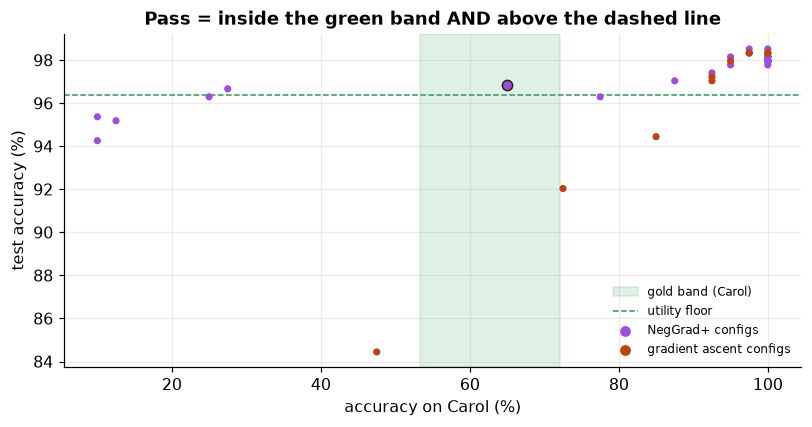

In [7]:
# Step 5b: sweep 46 reasonable configurations of the two ascent-based baselines and count how many pass
import itertools
sweep = {}
for a, lr, ep in itertools.product([0.99, 0.995, 0.999], [1e-4, 3e-4, 1e-3], [1, 2, 3, 5]):
    sweep[f"neggrad+ a={a} lr={lr} ep={ep}"] = methods.neggrad_plus(original, L.Xr, L.yr, L.Xf, L.yf, epochs=ep, alpha=a, lr=lr)[0]
for lr, ep in itertools.product([1e-4, 3e-4], [3, 4, 5, 6, 8]):
    sweep[f"gradient_ascent lr={lr} ep={ep}"] = methods.gradient_ascent(original, L.Xf, L.yf, epochs=ep, lr=lr)[0]
sw = audit.audit(sweep, splits, OUT, in_models=IN, mia=False).join(audit.gate(audit.audit(sweep, splits, OUT, in_models=IN, mia=False), band_mean, band_std))
print(f"configurations that PASS: {(sw.verdict == 'PASS').sum()} of {len(sw)}")
print(sw[sw.verdict == "PASS"][["forget_acc", "test_acc", "ulira"]].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
for name, r in sw.iterrows():
    c = viz.color_for(name.split()[0])
    ax.scatter(100 * r.forget_acc, 100 * r.test_acc, color=c, s=45 if r.verdict == "PASS" else 22,
               edgecolor=viz.INK if r.verdict == "PASS" else "none", zorder=3)
ax.axvspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="gold band (Carol)")
ax.axhline(100 * (band_mean["test_acc"] - 0.02), color=viz.RETRAIN, ls="--", lw=1, label="utility floor")
ax.scatter([], [], color=viz.color_for("neggrad+"), label="NegGrad+ configs"); ax.scatter([], [], color=viz.color_for("gradient_ascent"), label="gradient ascent configs")
ax.set_xlabel("accuracy on Carol (%)"); ax.set_ylabel("test accuracy (%)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Pass = inside the green band AND above the dashed line"); plt.tight_layout(); plt.show()

**One configuration out of 46.** Gradient ascent never passes : by the time Carol has fallen into the band, everyone
else's accuracy has fallen through the floor. NegGrad+ passes only at one exact combination of α, learning rate and
number of epochs - and we could only find it because, in this lab, we can *see* the gold band. In production you cannot.

![The forgetting spectrum](assets/diagrams/08_forget_spectrum.png)

> 🔴 **For practitioners :** gradient ascent on D_f is unbounded - cross-entropy can grow forever - which is why
> Zhang et al. (2024, NPO, in `resources/`) replace it with a bounded objective for LLMs (Problem 16). In this lab
> NegGrad+ needs α ≈ 0.99 : the forget signal must be tiny relative to the anchor, and the right α, learning rate and
> number of epochs **depend on the request**. That tuning problem - "when do I stop?" - is the central weakness of every
> approximate method, because in production you do **not** have the gold band to look at.

----
#### OUTCOME :

| Method | What happened | Typical failure |
|---|---|---|
| Fine-tune on D_r | Carol barely fades | under-forgetting (FORGET, PRIVACY) |
| Gradient ascent | forgets Carol, then everything | collateral damage (UTILITY); no stopping rule |
| NegGrad+ | forgets Carol while anchored to everyone else | passes in **1 of 46** settings; one epoch too many → over-forgets |

**The two things missing from all three :** a *reference* for what the model should say about Carol (not "as wrong as
possible", but "what a model that never saw her says"), and a *stopping rule* that does not need the gold standard.

#### Key Takeaways :

- **Gradient ascent = Newton's step without curvature** - natural, cheap, and unbounded.
- Without curvature you must **guess the step size**, and nothing tells you when to stop.
- **Anchoring** to the retain set (NegGrad+) limits collateral damage.
- Approximate methods fail in three directions - under-forget, over-forget, or break utility - and the window between
  them is tiny (1 of 46 settings here). They must be **audited**, every time.

#### TASK :
1. Re-run the NegGrad+ trajectory with `alpha = 0.95` and `alpha = 0.999`. Which fails FORGET, which fails UTILITY?
2. Run gradient ascent on `lab.make_lab("class")` (forget the digit 3). Does the collapse still happen? Is there a natural
   stopping point when the target is 0%?
3. Add an early-stop rule to gradient ascent : stop when Carol's accuracy falls to the accuracy on `L.X_like_forget`
   (unseen digits in her style). Does it pass the audit? Why is that a fair rule you could use in production?
4. Fine-tune for 50 epochs. Does Carol ever enter the band? Plot it.

#### ❓ Open question → Problem 9
Gradient ascent asks "be **wrong** on Carol". But the gold standard is not wrong on Carol - it is *uninformed* about her.
**What if, instead of climbing her loss, we used the original model as a reference - stay identical to it on everyone
else, and specifically move away from it on Carol - and kept a checkpoint at every step so we can rewind if we go too
far?** That is SCRUB.